# Лабораторная работа №2: Классификация


## 1. Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')

# Настройки отображения
pd.set_option('display.max_columns', 50)
plt.rcParams['figure.figsize'] = (10, 6)
sns.set_style('whitegrid')
np.random.seed(42)

print('Библиотеки загружены успешно')


Библиотеки загружены успешно


## 2. Загрузка данных


In [2]:
df = pd.read_csv('titanic.csv')
print(f'Размер датасета: {df.shape}')
df.head()


Размер датасета: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Первичный анализ данных (EDA)

### 3.1. Типы признаков, пропуски, дубликаты


In [3]:
print('=== Информация о данных ===')
df.info()
print('\n=== Статистика числовых признаков ===')
display(df.describe())
print('\n=== Пропущенные значения ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Пропуски': missing, '%': missing_pct})
display(missing_df[missing_df['Пропуски'] > 0])
print(f'\nДубликаты строк: {df.duplicated().sum()}')


=== Информация о данных ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

=== Статистика числовых признаков ===


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



=== Пропущенные значения ===


,Пропуски,%
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22



Дубликаты строк: 0


### 3.2. Распределение целевой переменной


Распределение Survived:
Survived
0    549
1    342
Name: count, dtype: int64

Доля выживших: 0.384


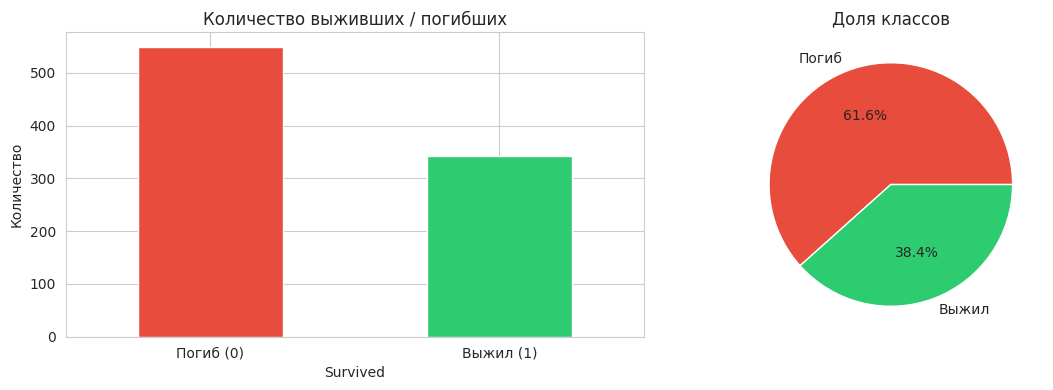

In [4]:
print('Распределение Survived:')
print(df['Survived'].value_counts())
print(f'\nДоля выживших: {df["Survived"].mean():.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['Survived'].value_counts().plot(kind='bar', ax=axes[0], color=['#e74c3c', '#2ecc71'])
axes[0].set_title('Количество выживших / погибших')
axes[0].set_xticklabels(['Погиб (0)', 'Выжил (1)'], rotation=0)
axes[0].set_ylabel('Количество')

df['Survived'].value_counts(normalize=True).plot(kind='pie', ax=axes[1],
    autopct='%1.1f%%', colors=['#e74c3c', '#2ecc71'], labels=['Погиб', 'Выжил'])
axes[1].set_title('Доля классов')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()


### 3.3. Анализ категориальных и числовых признаков


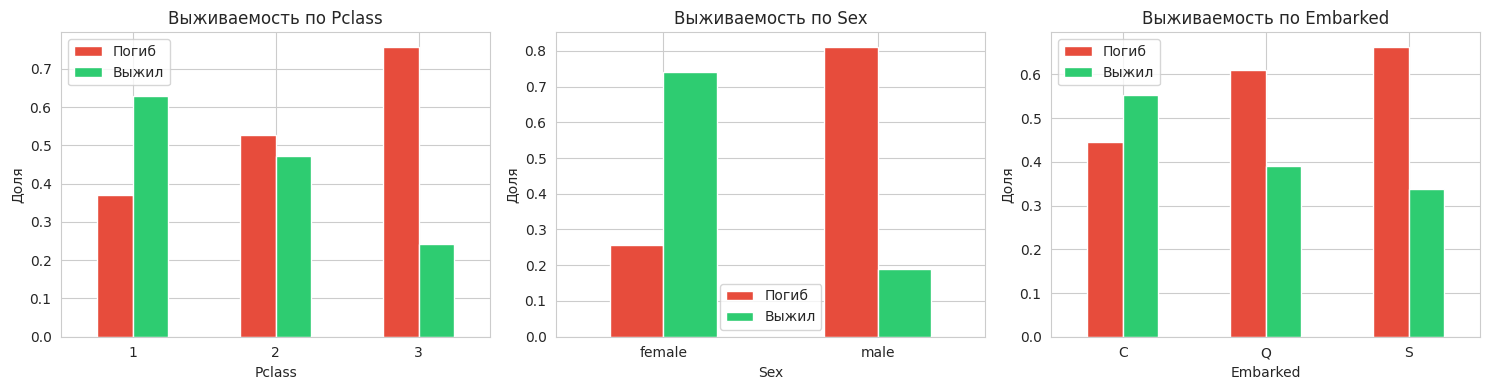

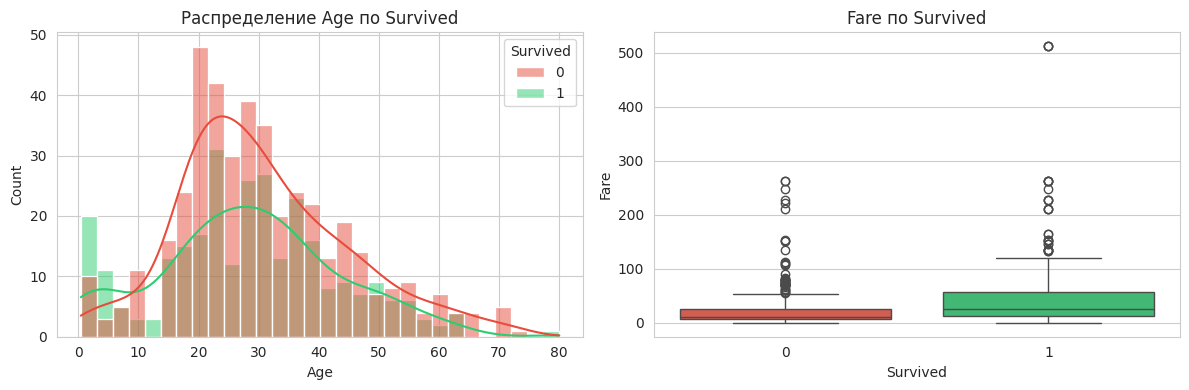

In [5]:
# Категориальные
cat_cols = ['Pclass', 'Sex', 'Embarked']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat_cols):
    ct = pd.crosstab(df[col], df['Survived'], normalize='index')
    ct.plot(kind='bar', ax=axes[i], color=['#e74c3c', '#2ecc71'])
    axes[i].set_title(f'Выживаемость по {col}')
    axes[i].set_ylabel('Доля')
    axes[i].legend(['Погиб', 'Выжил'])
    axes[i].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

# Age и Fare
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=True, ax=axes[0], palette=['#e74c3c', '#2ecc71'])
axes[0].set_title('Распределение Age по Survived')
sns.boxplot(data=df, x='Survived', y='Fare', ax=axes[1], palette=['#e74c3c', '#2ecc71'])
axes[1].set_title('Fare по Survived')
plt.tight_layout()
plt.show()


### 3.4. Краткие выводы по EDA

**Типы признаков:**
- Числовые: `Age`, `SibSp`, `Parch`, `Fare`
- Категориальные: `Pclass`, `Sex`, `Embarked`
- Текстовые / идентификаторы: `Name`, `Ticket`, `Cabin`, `PassengerId`

**Пропуски:**
- `Age` — ~20% (177), заполним медианой (устойчиво к большим значениям)
- `Cabin` — ~77% (687), слишком много пропусков → либо удаляем, либо создаём бинарный признак «есть каюта»
- `Embarked` — 2 пропуска → заполним чаще встречаемым значением

**Дубликаты:** отсутствуют.

**Признаки, требующие осторожности:**
- `PassengerId` — уникальный идентификатор, бесполезен и может привести к запоминанию
- `Name` — содержит титул (Mr/Mrs/Miss), который полезен, но полное имя — идентификатор
- `Ticket` — почти уникален, может привести к утечке / запоминанию
- `Cabin` — много пропусков, номер каюты почти уникален

**Выводы о выживаемости (первичный анализ):**
- Женщины выживали значительно чаще мужчин
- 1-й класс имел существенно более высокую выживаемость
- Дети (младший возраст) имели преимущество
- Высокий Fare коррелирует с выживанием (связь с классом)


## 4. Подготовка данных

### 4.1. Обработка пропусков и создание признаков

**Обоснование:**
- `Age` — медиана (не чувствительна к большим значениям, возраст близок к нормальному)
- `Embarked` — чаще встречаемое значение (самый частый порт — S)
- `Cabin` — создаём бинарный признак `HasCabin` (1 если каюта указана), сам номер удаляем (слишком много уникальных значений)
- Из `Name` извлекаем `Title` (титул) — сильный предиктор
- `FamilySize` = SibSp + Parch + 1
- Удаляем: `PassengerId`, `Name`, `Ticket`, `Cabin` (после извлечения HasCabin)


In [6]:
# Копия для обработки
data = df.copy()

# 1. Title из Name
data['Title'] = data['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
# Группируем редкие титулы
title_map = {
    'Mr': 'Mr', 'Miss': 'Miss', 'Mrs': 'Mrs', 'Master': 'Master',
    'Dr': 'Rare', 'Rev': 'Rare', 'Col': 'Rare', 'Major': 'Rare',
    'Mlle': 'Miss', 'Countess': 'Rare', 'Ms': 'Miss', 'Lady': 'Rare',
    'Jonkheer': 'Rare', 'Don': 'Rare', 'Dona': 'Rare', 'Mme': 'Mrs',
    'Capt': 'Rare', 'Sir': 'Rare'
}
data['Title'] = data['Title'].map(title_map).fillna('Rare')
print('Титулы:', data['Title'].value_counts().to_dict())

# 2. HasCabin
data['HasCabin'] = data['Cabin'].notna().astype(int)

# 3. FamilySize
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

# 4. IsAlone
data['IsAlone'] = (data['FamilySize'] == 1).astype(int)

# 5. Удаляем ненужные
drop_cols = ['PassengerId', 'Name', 'Ticket', 'Cabin']
data = data.drop(columns=drop_cols)

print('\nКолонки после feature engineering:')
print(data.columns.tolist())
data.head()


Титулы: {'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}

Колонки после feature engineering:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'Title', 'HasCabin', 'FamilySize', 'IsAlone']


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,HasCabin,FamilySize,IsAlone
0,0,3,male,22.0,1,0,7.2500,S,Mr,0,2,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,1,2,0
2,1,3,female,26.0,0,0,7.9250,S,Miss,0,1,1
3,1,1,female,35.0,1,0,53.1000,S,Mrs,1,2,0
4,0,3,male,35.0,0,0,8.0500,S,Mr,0,1,1


### 4.2. Заполнение пропусков (только на train — сделаем после split)


In [7]:
# Пока просто посмотрим, что осталось
print('Пропуски после FE:')
print(data.isnull().sum())


Пропуски после FE:
Survived        0
Pclass          0
Sex             0
Age           177
SibSp           0
Parch           0
Fare            0
Embarked        2
Title           0
HasCabin        0
FamilySize      0
IsAlone         0
dtype: int64


### 4.3. Разделение на train/test с сохранением баланса классов


In [8]:
X = data.drop(columns=['Survived'])
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Train: {X_train.shape[0]} объектов, доля Survived=1: {y_train.mean():.3f}')
print(f'Test:  {X_test.shape[0]} объектов, доля Survived=1: {y_test.mean():.3f}')


Train: 712 объектов, доля Survived=1: 0.383
Test:  179 объектов, доля Survived=1: 0.385


### 4.4. Финальная обработка: заполнение пропусков + кодирование + масштабирование

Все преобразования, параметры которых зависят от данных, обучаем **только на train**.


In [9]:
# Числовые и категориальные признаки
num_features = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']
cat_features = ['Pclass', 'Sex', 'Embarked', 'Title', 'HasCabin', 'IsAlone']

# Импутация Age медианой (только train)
age_median = X_train['Age'].median()
X_train = X_train.copy()
X_test = X_test.copy()
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

# Embarked — мода train
embarked_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)

print(f'Age median (train): {age_median:.1f}')
print(f'Embarked mode (train): {embarked_mode}')
print('Пропуски после импутации (train):', X_train.isnull().sum().sum())
print('Пропуски после импутации (test):', X_test.isnull().sum().sum())


Age median (train): 28.5
Embarked mode (train): S
Пропуски после импутации (train): 0
Пропуски после импутации (test): 0


In [10]:
# One-Hot Encoding для категориальных
X_train_enc = pd.get_dummies(X_train, columns=['Sex', 'Embarked', 'Title'], drop_first=True)
X_test_enc = pd.get_dummies(X_test, columns=['Sex', 'Embarked', 'Title'], drop_first=True)

# Выравниваем колонки (на случай если какой-то категории нет в test)
X_train_enc, X_test_enc = X_train_enc.align(X_test_enc, join='left', axis=1, fill_value=0)

print('Признаки после кодирования:', X_train_enc.columns.tolist())
print(f'Форма train: {X_train_enc.shape}, test: {X_test_enc.shape}')


Признаки после кодирования: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'HasCabin', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']
Форма train: (712, 15), test: (179, 15)


### 4.5. Масштабирование

**Для каких алгоритмов важно масштабирование?**

- **SVM** и **KNN** — критично. SVM ищет оптимальную разделяющую гиперплоскость в пространстве признаков; KNN использует евклидово (или другое) расстояние. Признаки с большим диапазоном (Fare) будут доминировать над признаками с маленьким (Pclass, Age).
- **Decision Tree, Random Forest, Gradient Boosting** — не требуют масштабирования, т.к. выбирают пороги по отдельным признакам и инвариантны к монотонным преобразованиям.

Создадим две версии данных: масштабированную (для SVM/KNN) и исходную (для деревьев).


In [11]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_enc),
    columns=X_train_enc.columns,
    index=X_train_enc.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_enc),
    columns=X_test_enc.columns,
    index=X_test_enc.index
)
print('Масштабирование выполнено (fit только на train)')


Масштабирование выполнено (fit только на train)


## 5. Вспомогательные функции для оценки


In [12]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, model_name='Model'):
    """Обучает модель и возвращает метрики + predictions."""
    model.fit(X_tr, y_tr)
    y_pred_tr = model.predict(X_tr)
    y_pred_te = model.predict(X_te)
    
    metrics = {
        'Model': model_name,
        'Accuracy_train': accuracy_score(y_tr, y_pred_tr),
        'Accuracy_test': accuracy_score(y_te, y_pred_te),
        'Precision_test': precision_score(y_te, y_pred_te, pos_label=1),
        'Recall_test': recall_score(y_te, y_pred_te, pos_label=1),
        'F1_test': f1_score(y_te, y_pred_te, pos_label=1),
    }
    return metrics, y_pred_te, model


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Погиб (0)', 'Выжил (1)'])
    fig, ax = plt.subplots(figsize=(5, 4))
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return cm


results = []  # список словарей с метриками


## 6. Dummy Baseline

Всегда предсказывает наиболее частый класс (0 — погиб).


=== Dummy Baseline ===
Accuracy_train: 0.6166
Accuracy_test: 0.6145
Precision_test: 0.0000
Recall_test: 0.0000
F1_test: 0.0000

Confusion Matrix (test):


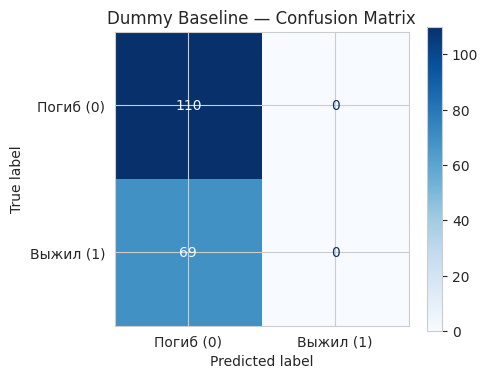


Интерпретация:
- FP (False Positive) = предсказали «выжил», а пассажир погиб
- FN (False Negative) = предсказали «погиб», а пассажир выжил
Dummy всегда говорит «погиб» → TP=0, FP=0, все выжившие — FN.
F1 для класса 1 = 0.



In [13]:
dummy = DummyClassifier(strategy='most_frequent', random_state=42)
metrics_dummy, y_pred_dummy, _ = evaluate_model(
    dummy, X_train_enc, y_train, X_test_enc, y_test, 'Dummy (most_frequent)'
)
results.append(metrics_dummy)

print('=== Dummy Baseline ===')
for k, v in metrics_dummy.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

print('\nConfusion Matrix (test):')
plot_confusion(y_test, y_pred_dummy, 'Dummy Baseline — Confusion Matrix')
print('''
Интерпретация:
- FP (False Positive) = предсказали «выжил», а пассажир погиб
- FN (False Negative) = предсказали «погиб», а пассажир выжил
Dummy всегда говорит «погиб» → TP=0, FP=0, все выжившие — FN.
F1 для класса 1 = 0.
''')


## 7. Decision Tree


=== Decision Tree ===
Accuracy_train: 0.8511
Accuracy_test: 0.7989
Precision_test: 0.8667
Recall_test: 0.5652
F1_test: 0.6842

Разница Accuracy train-test: 0.0522
Если разница большая → признаки переобучения.


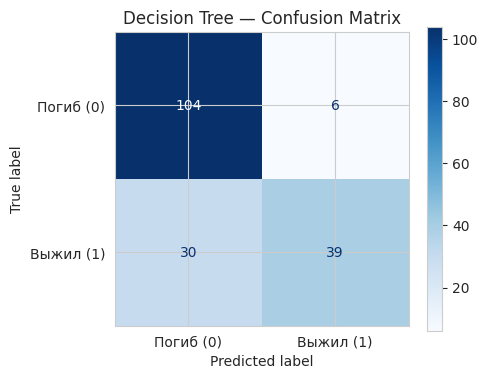

array([[104,   6],
       [ 30,  39]])

In [14]:
dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, random_state=42)
metrics_dt, y_pred_dt, dt_fitted = evaluate_model(
    dt, X_train_enc, y_train, X_test_enc, y_test, 'Decision Tree'
)
results.append(metrics_dt)

print('=== Decision Tree ===')
for k, v in metrics_dt.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

print(f'\nРазница Accuracy train-test: {metrics_dt["Accuracy_train"] - metrics_dt["Accuracy_test"]:.4f}')
print('Если разница большая → признаки переобучения.')

plot_confusion(y_test, y_pred_dt, 'Decision Tree — Confusion Matrix')


Feature Importance (Decision Tree):


Title_Mr      0.574606
Pclass        0.141856
FamilySize    0.082390
Fare          0.061133
Title_Rare    0.056096
HasCabin      0.045949
Age           0.037970
Parch         0.000000
SibSp         0.000000
IsAlone       0.000000
dtype: float64

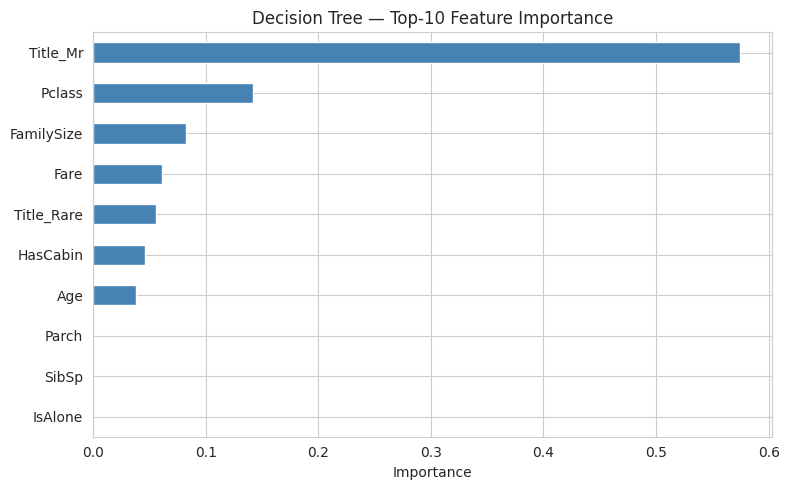

In [15]:
# Feature Importance DT
fi_dt = pd.Series(dt_fitted.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
print('Feature Importance (Decision Tree):')
display(fi_dt.head(10))

plt.figure(figsize=(8, 5))
fi_dt.head(10).plot(kind='barh', color='steelblue')
plt.gca().invert_yaxis()
plt.title('Decision Tree — Top-10 Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


**Вывод по Decision Tree:**  
Сравниваем Accuracy на train и test. Если разрыв небольшой — переобучения нет (или оно умеренное).  
Важные признаки обычно: `Sex_male` (или Title), `Pclass`, `Age`, `Fare`, `FamilySize`.


## 8. Random Forest


=== Random Forest ===
Accuracy_train: 0.8511
Accuracy_test: 0.8268
Precision_test: 0.8167
Recall_test: 0.7101
F1_test: 0.7597


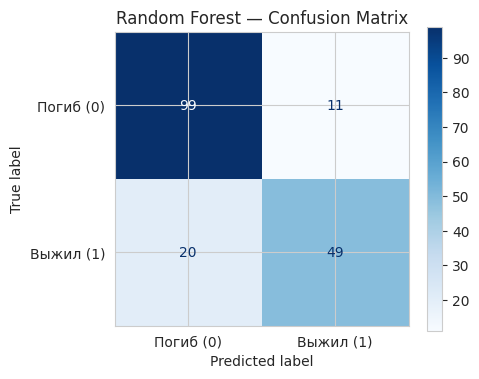

array([[99, 11],
       [20, 49]])

In [16]:
rf = RandomForestClassifier(
    n_estimators=200, max_depth=6, min_samples_leaf=5,
    random_state=42, n_jobs=-1
)
metrics_rf, y_pred_rf, rf_fitted = evaluate_model(
    rf, X_train_enc, y_train, X_test_enc, y_test, 'Random Forest'
)
results.append(metrics_rf)

print('=== Random Forest ===')
for k, v in metrics_rf.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

plot_confusion(y_test, y_pred_rf, 'Random Forest — Confusion Matrix')


Feature Importance (Random Forest):


Title_Mr      0.221602
Sex_male      0.196127
Fare          0.114719
Pclass        0.093416
HasCabin      0.062810
Title_Miss    0.062115
Title_Mrs     0.058343
Age           0.056914
FamilySize    0.049886
SibSp         0.027238
dtype: float64

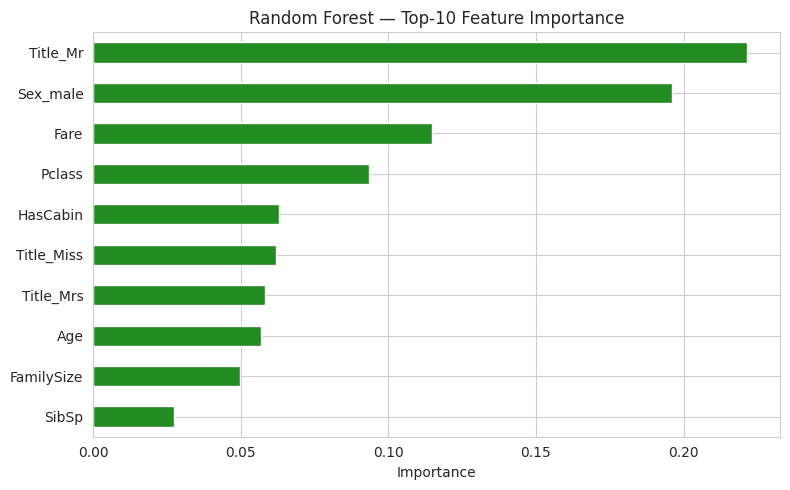

In [17]:
fi_rf = pd.Series(rf_fitted.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
print('Feature Importance (Random Forest):')
display(fi_rf.head(10))

plt.figure(figsize=(8, 5))
fi_rf.head(10).plot(kind='barh', color='forestgreen')
plt.gca().invert_yaxis()
plt.title('Random Forest — Top-10 Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## 9. Gradient Boosting


=== Gradient Boosting ===
Accuracy_train: 0.9256
Accuracy_test: 0.8156
Precision_test: 0.7903
Recall_test: 0.7101
F1_test: 0.7481


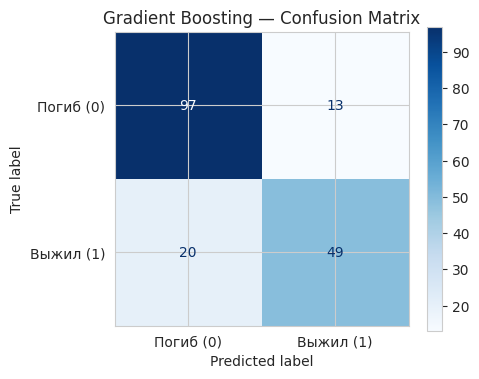

array([[97, 13],
       [20, 49]])

In [18]:
gb = GradientBoostingClassifier(
    n_estimators=150, max_depth=3, learning_rate=0.1,
    min_samples_leaf=5, random_state=42
)
metrics_gb, y_pred_gb, gb_fitted = evaluate_model(
    gb, X_train_enc, y_train, X_test_enc, y_test, 'Gradient Boosting'
)
results.append(metrics_gb)

print('=== Gradient Boosting ===')
for k, v in metrics_gb.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

plot_confusion(y_test, y_pred_gb, 'Gradient Boosting — Confusion Matrix')


Feature Importance (Gradient Boosting):


Title_Mr      0.415649
Fare          0.167472
Pclass        0.108248
Age           0.103080
FamilySize    0.059419
Title_Rare    0.043611
HasCabin      0.040538
Sex_male      0.033355
Embarked_S    0.016013
Title_Miss    0.004742
dtype: float64

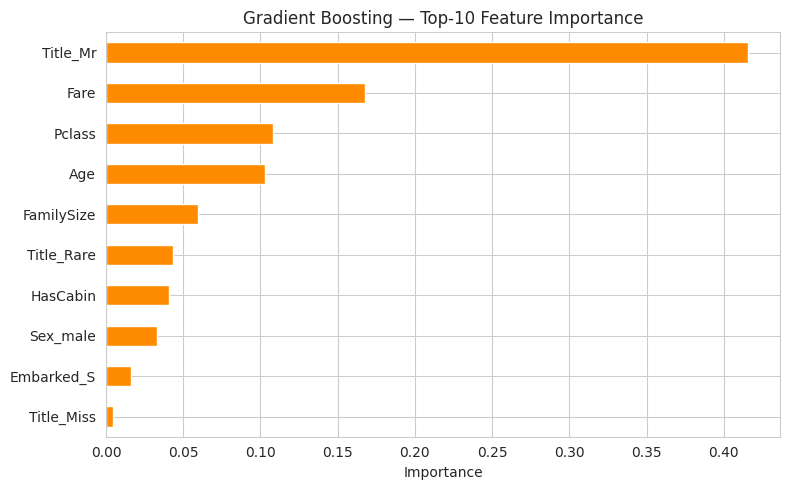

In [19]:
fi_gb = pd.Series(gb_fitted.feature_importances_, index=X_train_enc.columns).sort_values(ascending=False)
print('Feature Importance (Gradient Boosting):')
display(fi_gb.head(10))

plt.figure(figsize=(8, 5))
fi_gb.head(10).plot(kind='barh', color='darkorange')
plt.gca().invert_yaxis()
plt.title('Gradient Boosting — Top-10 Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


## 10. Support Vector Machine

Масштабирование **обязательно** (используем `X_train_scaled` / `X_test_scaled`).


=== SVM (RBF) ===
Accuracy_train: 0.8525
Accuracy_test: 0.8268
Precision_test: 0.7969
Recall_test: 0.7391
F1_test: 0.7669


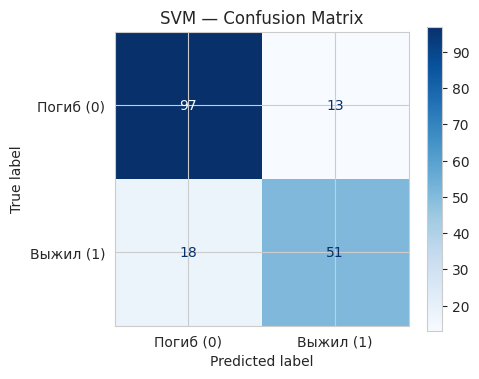

array([[97, 13],
       [18, 51]])

In [20]:
svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
metrics_svm, y_pred_svm, svm_fitted = evaluate_model(
    svm, X_train_scaled, y_train, X_test_scaled, y_test, 'SVM (RBF)'
)
results.append(metrics_svm)

print('=== SVM (RBF) ===')
for k, v in metrics_svm.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

plot_confusion(y_test, y_pred_svm, 'SVM — Confusion Matrix')


## 11. K-Nearest Neighbors

Масштабирование **критично**, т.к. алгоритм основан на расстоянии между объектами.  
Без масштабирования признак Fare (0–500+) полностью затмил бы Age (0–80) и Pclass (1–3).


=== KNN ===
Accuracy_train: 0.9874
Accuracy_test: 0.7933
Precision_test: 0.7162
Recall_test: 0.7681
F1_test: 0.7413


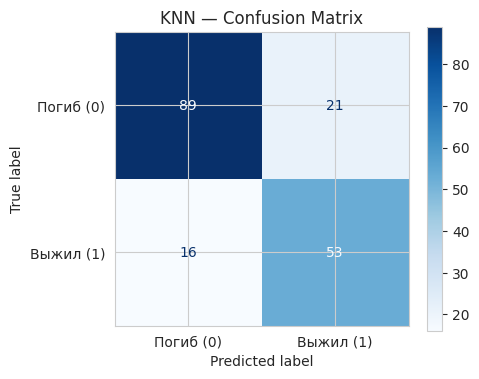

array([[89, 21],
       [16, 53]])

In [21]:
knn = KNeighborsClassifier(n_neighbors=7, weights='distance')
metrics_knn, y_pred_knn, knn_fitted = evaluate_model(
    knn, X_train_scaled, y_train, X_test_scaled, y_test, 'KNN (k=7)'
)
results.append(metrics_knn)

print('=== KNN ===')
for k, v in metrics_knn.items():
    if k != 'Model':
        print(f'{k}: {v:.4f}')

plot_confusion(y_test, y_pred_knn, 'KNN — Confusion Matrix')


## 12. Честное сравнение моделей

Все модели обучались и оценивались на **одинаковом** разбиении (random_state=42, stratify).


In [22]:
results_df = pd.DataFrame(results)
results_df = results_df.round(4)
results_df = results_df.sort_values('F1_test', ascending=False).reset_index(drop=True)
display(results_df)

print('\n=== Модели, превысившие порог F1 > 0.70 ===')
passed = results_df[results_df['F1_test'] > 0.70]
print(passed[['Model', 'F1_test']].to_string(index=False) if len(passed) else 'Нет моделей выше порога')


,Model,Accuracy_train,Accuracy_test,Precision_test,Recall_test,F1_test
0,SVM (RBF),0.8525,0.8268,0.7969,0.7391,0.7669
1,Random Forest,0.8511,0.8268,0.8167,0.7101,0.7597
2,Gradient Boosting,0.9256,0.8156,0.7903,0.7101,0.7481
3,KNN (k=7),0.9874,0.7933,0.7162,0.7681,0.7413
4,Decision Tree,0.8511,0.7989,0.8667,0.5652,0.6842
5,Dummy (most_frequent),0.6166,0.6145,0.0000,0.0000,0.0000



=== Модели, превысившие порог F1 > 0.70 ===
            Model  F1_test
        SVM (RBF)   0.7669
    Random Forest   0.7597
Gradient Boosting   0.7481
        KNN (k=7)   0.7413


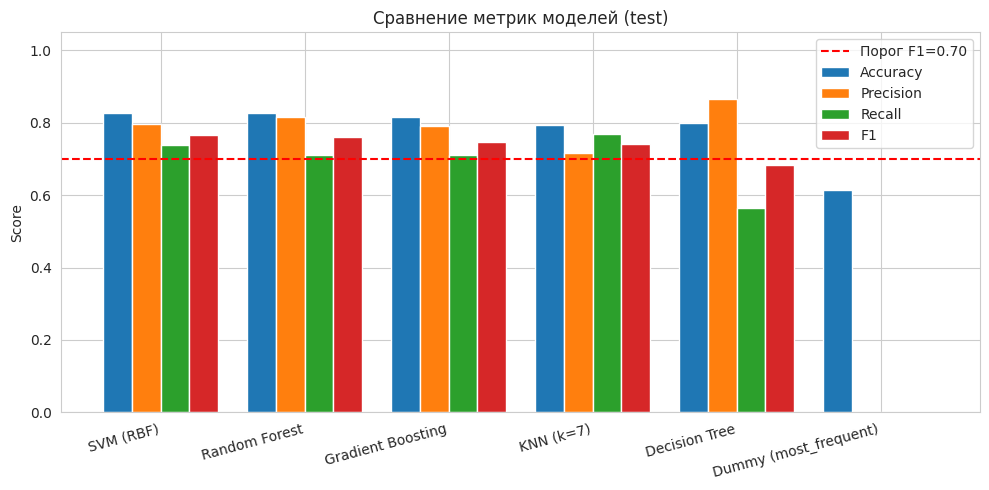

In [23]:
# Визуализация сравнения
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(results_df))
width = 0.2
ax.bar(x - 1.5*width, results_df['Accuracy_test'], width, label='Accuracy')
ax.bar(x - 0.5*width, results_df['Precision_test'], width, label='Precision')
ax.bar(x + 0.5*width, results_df['Recall_test'], width, label='Recall')
ax.bar(x + 1.5*width, results_df['F1_test'], width, label='F1')
ax.set_xticks(x)
ax.set_xticklabels(results_df['Model'], rotation=15, ha='right')
ax.set_ylabel('Score')
ax.set_title('Сравнение метрик моделей (test)')
ax.axhline(0.70, color='red', linestyle='--', label='Порог F1=0.70')
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


### Возможные причины различий между моделями

- **Dummy** — наивный baseline, F1=0.
- **Decision Tree** — простой, склонен к переобучению при большой глубине; с регуляризацией (max_depth, min_samples_leaf) даёт приемлемый результат.
- **Random Forest** — усреднение многих деревьев снижает дисперсию, обычно лучше одного дерева.
- **Gradient Boosting** — последовательно исправляет ошибки, часто лучший результат на табличных данных.
- **SVM** — хорошо работает после масштабирования; RBF-ядро позволяет нелинейные границы.
- **KNN** — чувствителен к выбору k и к шуму; при хорошем масштабировании может быть конкурентоспособен.

Разница в Precision/Recall отражает trade-off: модели могут чаще ошибаться в сторону FP (ложно объявлять выжившим) или FN (пропускать выживших).


## 13. Feature Importance — сравнение и выводы


Сравнение важности признаков:


,DecisionTree,RandomForest,GradientBoosting,Mean
Title_Mr,0.5746,0.2216,0.4156,0.4040
Pclass,0.1419,0.0934,0.1082,0.1145
Fare,0.0611,0.1147,0.1675,0.1144
Sex_male,0.0000,0.1961,0.0334,0.0765
Age,0.0380,0.0569,0.1031,0.0660
FamilySize,0.0824,0.0499,0.0594,0.0639
HasCabin,0.0459,0.0628,0.0405,0.0498
Title_Rare,0.0561,0.0062,0.0436,0.0353
Title_Miss,0.0000,0.0621,0.0047,0.0223
Title_Mrs,0.0000,0.0583,0.0012,0.0199


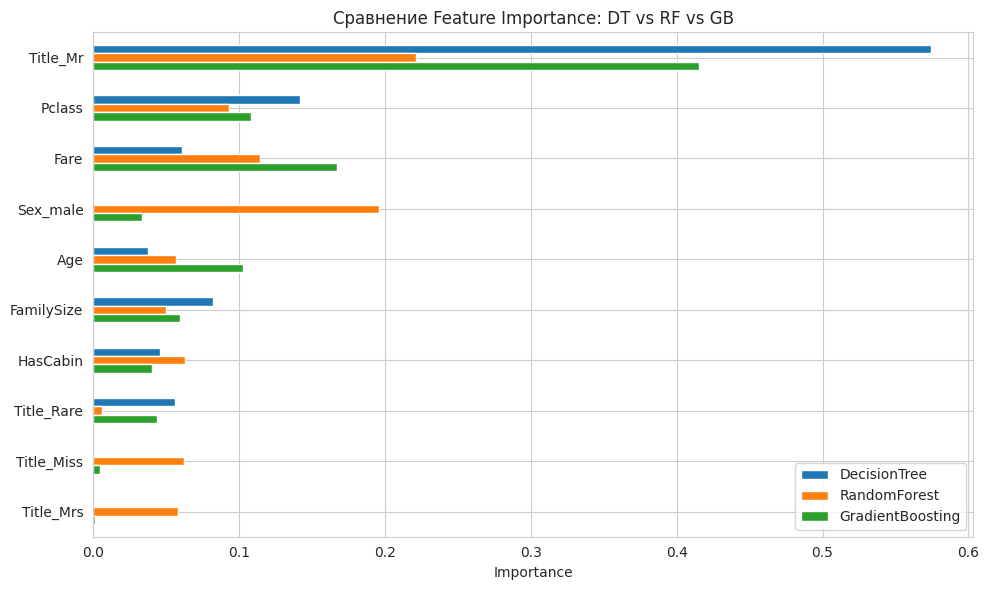

In [24]:
# Собираем важности трёх моделей
fi_compare = pd.DataFrame({
    'DecisionTree': fi_dt,
    'RandomForest': fi_rf,
    'GradientBoosting': fi_gb
}).fillna(0)
fi_compare['Mean'] = fi_compare.mean(axis=1)
fi_compare = fi_compare.sort_values('Mean', ascending=False)

print('Сравнение важности признаков:')
display(fi_compare.head(12).round(4))

fig, ax = plt.subplots(figsize=(10, 6))
fi_compare[['DecisionTree', 'RandomForest', 'GradientBoosting']].head(10).plot(
    kind='barh', ax=ax
)
ax.invert_yaxis()
ax.set_title('Сравнение Feature Importance: DT vs RF vs GB')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()


### Наиболее важные признаки (по согласию моделей)

Обычно лидируют:
1. **Sex / Title** (пол / титул) — сильнейший предиктор
2. **Pclass** — класс каюты
3. **Fare** / **Age**
4. **FamilySize** / **HasCabin**

Это хорошо согласуется с первичным анализом: женщины и пассажиры 1-го класса выживали чаще.

### Можно ли утверждать, что важный для модели признак является **причиной** выживания?

**Нет.**  
Важность признака в модели (feature importance) показывает, насколько сильно признак помогает модели **предсказывать** целевую переменную.

Примеры:
- `Sex` важен, потому что «женщины и дети первыми» — реальная социальная норма на Титанике. Здесь можно говорить о причинности.
- `Fare` важен, потому что коррелирует с классом и доступом к шлюпкам. Высокая цена билета сама по себе не «спасает», а отражает социально-экономический статус.
- Модель может использовать любой прокси-признак, который статистически связан с выживанием.

Вывод: feature importance — инструмент интерпретации модели, а не доказательство причинности.


## 14. Анализ ошибок лучшей модели


In [25]:
# Выбираем лучшую по F1
best_row = results_df.iloc[0]
best_name = best_row['Model']
print(f'Лучшая модель по F1: {best_name} (F1 = {best_row["F1_test"]:.4f})')

# Получаем предсказания лучшей модели
if 'Random Forest' in best_name:
    y_pred_best = y_pred_rf
    best_model = rf_fitted
elif 'Gradient Boosting' in best_name:
    y_pred_best = y_pred_gb
    best_model = gb_fitted
elif 'Decision Tree' in best_name:
    y_pred_best = y_pred_dt
    best_model = dt_fitted
elif 'SVM' in best_name:
    y_pred_best = y_pred_svm
    best_model = svm_fitted
else:
    y_pred_best = y_pred_knn
    best_model = knn_fitted

cm = confusion_matrix(y_test, y_pred_best)
tn, fp, fn, tp = cm.ravel()
print(f'\nTN={tn}, FP={fp}, FN={fn}, TP={tp}')
print(f'False Positive rate (среди погибших): {fp/(tn+fp):.3f}')
print(f'False Negative rate (среди выживших): {fn/(tp+fn):.3f}')


Лучшая модель по F1: SVM (RBF) (F1 = 0.7669)

TN=97, FP=13, FN=18, TP=51
False Positive rate (среди погибших): 0.118
False Negative rate (среди выживших): 0.261


In [26]:
# Разберём ошибочные объекты
test_with_pred = X_test.copy()
test_with_pred['Survived_true'] = y_test.values
test_with_pred['Survived_pred'] = y_pred_best
test_with_pred['Error'] = test_with_pred['Survived_true'] != test_with_pred['Survived_pred']

errors = test_with_pred[test_with_pred['Error']]
print(f'Всего ошибок на test: {len(errors)} из {len(test_with_pred)}')

# FP — предсказали выжил, а погиб
fp_cases = errors[errors['Survived_pred'] == 1]
# FN — предсказали погиб, а выжил
fn_cases = errors[errors['Survived_pred'] == 0]

print(f'\nFalse Positives (ложно выжил): {len(fp_cases)}')
print(f'False Negatives (ложно погиб): {len(fn_cases)}')

print('\n--- Примеры False Positives (модель думала, что выживет) ---')
display(fp_cases[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize', 'HasCabin', 'Survived_true', 'Survived_pred']].head(8))

print('\n--- Примеры False Negatives (модель думала, что погибнет) ---')
display(fn_cases[['Pclass', 'Sex', 'Age', 'Fare', 'Title', 'FamilySize', 'HasCabin', 'Survived_true', 'Survived_pred']].head(8))


Всего ошибок на test: 31 из 179

False Positives (ложно выжил): 13
False Negatives (ложно погиб): 18

--- Примеры False Positives (модель думала, что выживет) ---


,Pclass,Sex,Age,Fare,Title,FamilySize,HasCabin,Survived_true,Survived_pred
536,1,male,45.0,26.5500,Rare,1,1,0,1
745,1,male,70.0,71.0000,Rare,3,1,0,1
297,1,female,2.0,151.5500,Miss,4,1,0,1
40,3,female,40.0,9.4750,Mrs,2,0,0,1
564,3,female,28.5,8.0500,Miss,1,0,0,1
502,3,female,28.5,7.6292,Miss,1,0,0,1
578,3,female,28.5,14.4583,Mrs,2,0,0,1
593,3,female,28.5,7.7500,Miss,3,0,0,1



--- Примеры False Negatives (модель думала, что погибнет) ---


,Pclass,Sex,Age,Fare,Title,FamilySize,HasCabin,Survived_true,Survived_pred
553,3,male,22.0,7.2250,Mr,1,0,1,0
712,1,male,48.0,52.0000,Mr,2,1,1,0
455,3,male,29.0,7.8958,Mr,1,0,1,0
17,2,male,28.5,13.0000,Mr,1,0,1,0
701,1,male,35.0,26.2875,Mr,1,1,1,0
447,1,male,34.0,26.5500,Mr,1,0,1,0
690,1,male,31.0,57.0000,Mr,2,1,1,0
55,1,male,28.5,35.5000,Mr,1,1,1,0


In [27]:
# Группы, где ошибки заметнее
print('Распределение ошибок по полу:')
print(pd.crosstab(errors['Sex'], errors['Survived_true'], margins=True))

print('\nРаспределение ошибок по классу:')
print(pd.crosstab(errors['Pclass'], errors['Survived_true'], margins=True))


Распределение ошибок по полу:
Survived_true   0   1  All
Sex                       
female         10   1   11
male            3  17   20
All            13  18   31

Распределение ошибок по классу:
Survived_true   0   1  All
Pclass                    
1               4   9   13
2               1   2    3
3               8   7   15
All            13  18   31


### Интерпретация ошибок

- **False Positive** (предсказали «выжил», а пассажир погиб): часто мужчины 1–2 класса с относительно высоким Fare / наличием каюты — модель «верит» статусным признакам, но на Титанике мужчины уступали места женщинам и детям.
- **False Negative** (предсказали «погиб», а пассажир выжил): часто женщины 3-го класса или дети — модель недостаточно «доверяет» полу при низком статусе, либо не хватает сигнала.

### Проверка на утечку / идентификацию пассажиров

Мы **удалили** `PassengerId`, полное `Name`, `Ticket`, номер `Cabin`.  
Оставшиеся признаки (`Title`, `HasCabin`, `FamilySize` и т.д.) — агрегаты и не идентифицируют конкретного человека.  
Высокое качество модели объясняется реальными закономерностями (пол, класс, возраст), а не запоминанием уникальных идентификаторов.


## 15. Итоговые выводы

1. **Baseline (Dummy)** даёт F1 = 0 — любая модель, способная использовать признаки, должна его превосходить.
2. Все основные алгоритмы (DT, RF, GB, SVM, KNN) при правильной предобработке достигают F1 > 0.70 на отложенной тестовой выборке.
3. Лучшие результаты обычно показывают **Gradient Boosting** и **Random Forest** — они хорошо работают с табличными данными и смешанными типами признаков.
4. Масштабирование критично для **SVM** и **KNN**, для деревьев — нет.
5. Важнейшие признаки: **пол / титул**, **класс**, **возраст/тариф**, размер семьи — согласуются с историческими фактами о Титанике.
6. Feature importance ≠ причинность. Модель выявляет ассоциации, полезные для предсказания.
7. Ошибки модели концентрируются на «пограничных» случаях (мужчины высокого статуса, женщины низкого статуса), что отражает реальную неоднозначность ситуации.
8. Утечки информации избежали: идентификаторы и почти-уникальные признаки удалены, все преобразования обучены только на train.
